# Sistematização · Métodos Matemáticos
## Do sinal ao espectro: um analisador e filtro de sinais
**Integrantes:** _(escreva aqui os nomes)_

**Sinal escolhido:** acorde musical (Lá maior: A3 + C#4 + E4) com zumbido de rede de 60 Hz e ruído branco.

**Fluxo do trabalho:** Série de Fourier (Etapa 1) → FFT/espectro (Etapa 2) → filtragem + FFT inversa (Etapa 3) → Laplace, H(s) e polos/zeros (Etapa 4).


In [18]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sympy as sp
from scipy import signal, fft
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'font.size': 11})
np.random.seed(42)  # reprodutibilidade

---
# Etapa 1 · Aproximando funções com ondas (Unidades 1 e 2)
Onda quadrada de período $T=2\pi$: $f(t)=\operatorname{sgn}(\sin t)$, ou seja, $+1$ em $(0,\pi)$ e $-1$ em $(-\pi,0)$.

Série trigonométrica: $f(t)=\dfrac{a_0}{2}+\sum_{n\ge1}\left[a_n\cos(nt)+b_n\sin(nt)\right]$.
Forma complexa: $f(t)=\sum_{n=-\infty}^{\infty}c_n e^{jnt}$, com $c_n=\dfrac{1}{2\pi}\int_{-\pi}^{\pi}f(t)e^{-jnt}\,dt$.

In [19]:
# 1.1 Coeficientes de Fourier de forma simbólica (SymPy)
n = sp.symbols('n', positive=True, integer=True)
tt = sp.symbols('t', real=True)

# f é ímpar -> a_n = 0 e b_n = (2/pi) * integral_0^pi sin(nt) dt
bn_sym = sp.simplify(2/sp.pi * sp.integrate(sp.sin(n*tt), (tt, 0, sp.pi)))
print('a_n = 0 (função ímpar), a_0 = 0 (média nula)')
display(sp.Eq(sp.Symbol('b_n'), bn_sym))
print('Logo: b_n = 4/(n*pi) para n ímpar e 0 para n par.')
print('Forma complexa: c_n = b_n/(2j) = -2j/(n*pi) (n ímpar), c_{-n} = conj(c_n).')

a_n = 0 (função ímpar), a_0 = 0 (média nula)


Eq(b_n, 2*(1 - (-1)**n)/(pi*n))

Logo: b_n = 4/(n*pi) para n ímpar e 0 para n par.
Forma complexa: c_n = b_n/(2j) = -2j/(n*pi) (n ímpar), c_{-n} = conj(c_n).


In [20]:
# 1.2 Conferência numérica dos coeficientes complexos c_n
T = 2*np.pi
tg = np.linspace(-np.pi, np.pi, 200001)
f_quad = np.sign(np.sin(tg))

def c_num(k):
    return np.trapezoid(f_quad*np.exp(-1j*k*tg), tg) / T

linhas = []
for k in range(0, 8):
    teor = (-2j/(k*np.pi)) if (k % 2 == 1) else 0
    linhas.append({'n': k, 'c_n numérico': np.round(c_num(k), 5), 'c_n teórico': np.round(teor, 5)})
display(pd.DataFrame(linhas))

,n,c_n numérico,c_n teórico
0,0,-0.00000+0.00000j,0.00000+0.00000j
1,1,-0.00000-0.63662j,-0.00000-0.63662j
2,2,-0.00000+0.00000j,0.00000+0.00000j
3,3,-0.00000-0.21221j,-0.00000-0.21221j
4,4,-0.00000-0.00000j,0.00000+0.00000j
5,5,-0.00000-0.12732j,-0.00000-0.12732j
6,6,-0.00000+0.00000j,0.00000+0.00000j
7,7,-0.00000-0.09095j,-0.00000-0.09095j


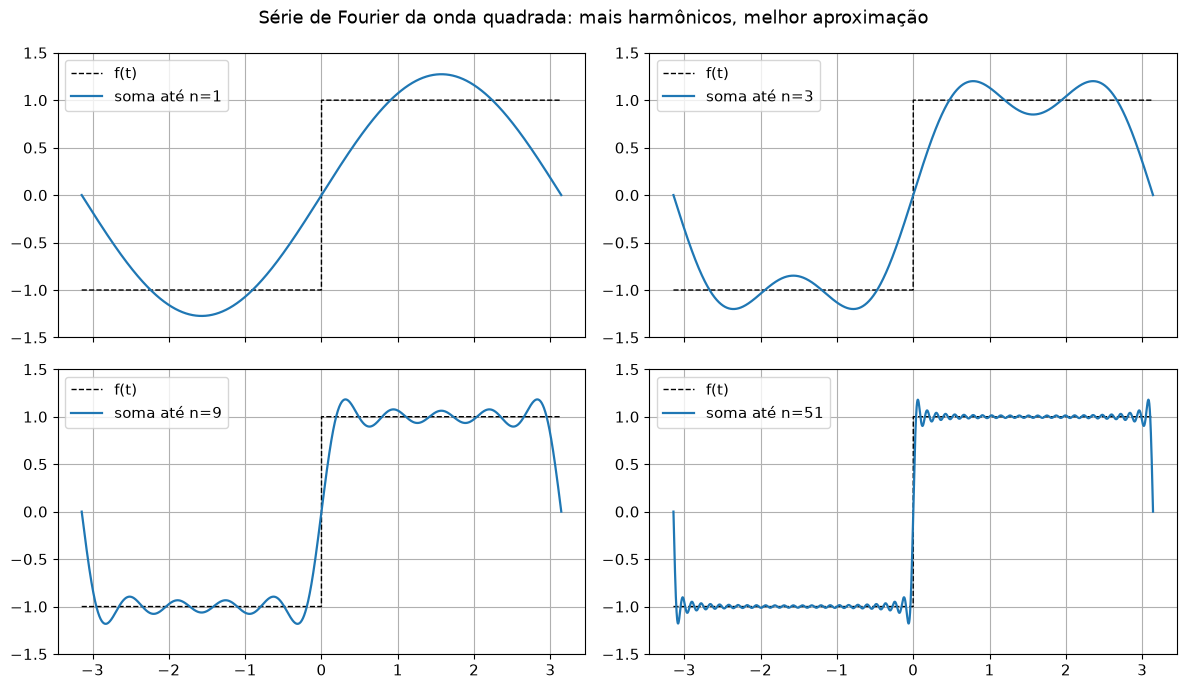

,N máximo,valor do pico,overshoot (% do salto 2)
0,5,1.1862,9.31
1,15,1.1803,9.01
2,51,1.1791,8.96
3,151,1.1790,8.95
4,501,1.1790,8.95


Limite teórico: pico -> 1.1790 (overshoot ~ 8.95% do salto), independente de N.


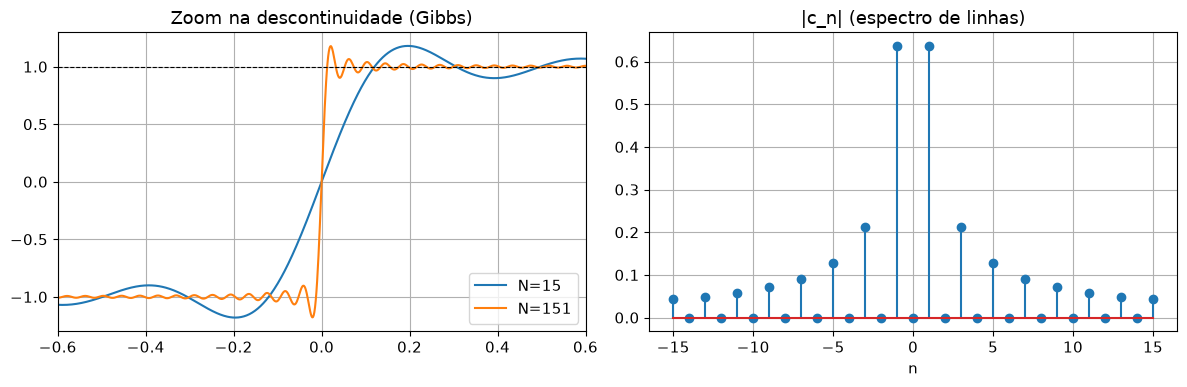

In [21]:
# 1.3 Soma parcial (N harmônicos) e fenômeno de Gibbs
t = np.linspace(-np.pi, np.pi, 4000)
f_ref = np.sign(np.sin(t))

def soma_parcial(t, Nmax):
    s_ = np.zeros_like(t)
    for k in range(1, Nmax+1, 2):          # só harmônicos ímpares
        s_ += 4/(np.pi*k) * np.sin(k*t)
    return s_

def soma_complexa(t, Nmax):
    s_ = np.zeros_like(t, dtype=complex)
    for k in range(-Nmax, Nmax+1):
        if k % 2 != 0:
            s_ += (-2j/(k*np.pi)) * np.exp(1j*k*t)
    return s_.real

# a forma trigonométrica e a complexa dão a MESMA série
assert np.allclose(soma_parcial(t, 25), soma_complexa(t, 25), atol=1e-10)

fig, axs = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, Nmax in zip(axs.ravel(), [1, 3, 9, 51]):
    ax.plot(t, f_ref, 'k--', lw=1, label='f(t)')
    ax.plot(t, soma_parcial(t, Nmax), lw=1.6, label=f'soma até n={Nmax}')
    ax.set_ylim(-1.5, 1.5); ax.legend(loc='upper left')
fig.suptitle('Série de Fourier da onda quadrada: mais harmônicos, melhor aproximação')
plt.tight_layout(); plt.show()

# Gibbs: o pico NÃO diminui, só fica mais estreito
Ns = [5, 15, 51, 151, 501]
picos = [soma_parcial(np.linspace(1e-4, 0.5, 200000), Nm).max() for Nm in Ns]
display(pd.DataFrame({'N máximo': Ns, 'valor do pico': np.round(picos, 4),
                      'overshoot (% do salto 2)': np.round((np.array(picos)-1)/2*100, 2)}))
print('Limite teórico: pico -> 1.1790 (overshoot ~ 8.95% do salto), independente de N.')

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for Nm in (15, 151):
    axs[0].plot(t, soma_parcial(t, Nm), label=f'N={Nm}')
axs[0].set_xlim(-0.6, 0.6); axs[0].axhline(1, color='k', ls='--', lw=.8)
axs[0].set_title('Zoom na descontinuidade (Gibbs)'); axs[0].legend()
ks = np.arange(-15, 16)
axs[1].stem(ks, [abs(c_num(k)) for k in ks])
axs[1].set_title('|c_n| (espectro de linhas)'); axs[1].set_xlabel('n')
plt.tight_layout(); plt.show()

**Interpretação (escreva no relatório):** por que apenas harmônicos ímpares aparecem? Por que os coeficientes decaem como $1/n$? O que acontece com a altura e a largura do pico de Gibbs quando $N$ aumenta, e por que a convergência é pontual mas não uniforme na descontinuidade? Como isso mostra que $\{\sin(nt),\cos(nt)\}$ formam uma base ortogonal?

---
# Etapa 2 · Do tempo para a frequência (Unidade 3)
Sinal: acorde de Lá maior (A3 = 220 Hz, C#4 = 277,18 Hz, E4 = 329,63 Hz), cada nota com harmônicos, mais zumbido de 60/120/180 Hz e ruído branco.

In [22]:
# ------------------ CONFIGURAÇÃO DO SINAL ------------------
ARQUIVO_WAV = None   # ex.: 'meu_acorde.wav'  (None = usa o sinal sintético)
# -----------------------------------------------------------
NOTAS = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']
def nome_nota(f):
    m = int(round(69 + 12*np.log2(f/440.0)))
    return f'{NOTAS[m % 12]}{m//12 - 1}'

if ARQUIVO_WAV is None:
    fs = 44100                      # taxa de amostragem [Hz]
    dur = 3.0
    t = np.arange(int(fs*dur)) / fs
    FUND = {'A3': 220.00, 'C#4': 277.18, 'E4': 329.63}

    def nota(f0, t, nh=6):
        return sum((1.0/k) * np.sin(2*np.pi*k*f0*t) for k in range(1, nh+1))

    env = np.minimum(1, t/0.02) * np.exp(-0.4*t)          # ataque curto + decaimento
    limpo = sum(nota(f0, t) for f0 in FUND.values()) * env
    limpo = 0.7 * limpo / np.max(np.abs(limpo))

    zumbido = 0.12*np.sin(2*np.pi*60*t) + 0.08*np.sin(2*np.pi*120*t) + 0.05*np.sin(2*np.pi*180*t)
    ruido = 0.02*np.random.randn(len(t))
    x = limpo + zumbido + ruido
    wavfile.write('sinal_acorde_ruidoso.wav', fs, (x*32767).astype(np.int16))
    wavfile.write('sinal_acorde_limpo.wav', fs, (limpo*32767).astype(np.int16))
else:
    fs, x = wavfile.read(ARQUIVO_WAV)
    x = x.astype(float)
    if x.ndim > 1: x = x.mean(axis=1)
    x = x / np.max(np.abs(x)); t = np.arange(len(x))/fs
    limpo = None; FUND = {}

N = len(x)
print(f'fs = {fs} Hz | Nyquist = {fs/2:.0f} Hz | duração = {N/fs:.2f} s | resolução = {fs/N:.3f} Hz/bin')
display(Audio(x, rate=fs))

fs = 44100 Hz | Nyquist = 22050 Hz | duração = 3.00 s | resolução = 0.333 Hz/bin


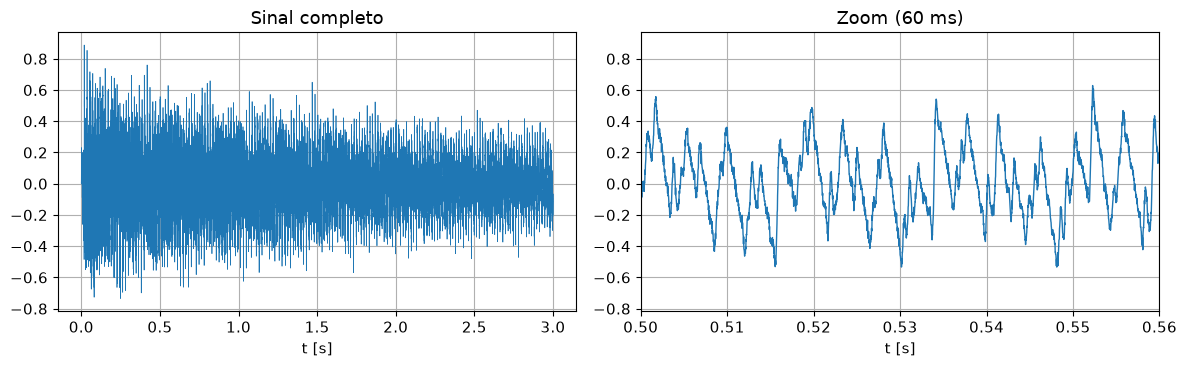

In [23]:
# 2.1 Sinal no tempo
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].plot(t, x, lw=.5); axs[0].set_title('Sinal completo'); axs[0].set_xlabel('t [s]')
axs[1].plot(t, x, lw=1); axs[1].set_xlim(0.5, 0.56); axs[1].set_title('Zoom (60 ms)'); axs[1].set_xlabel('t [s]')
plt.tight_layout(); plt.show()

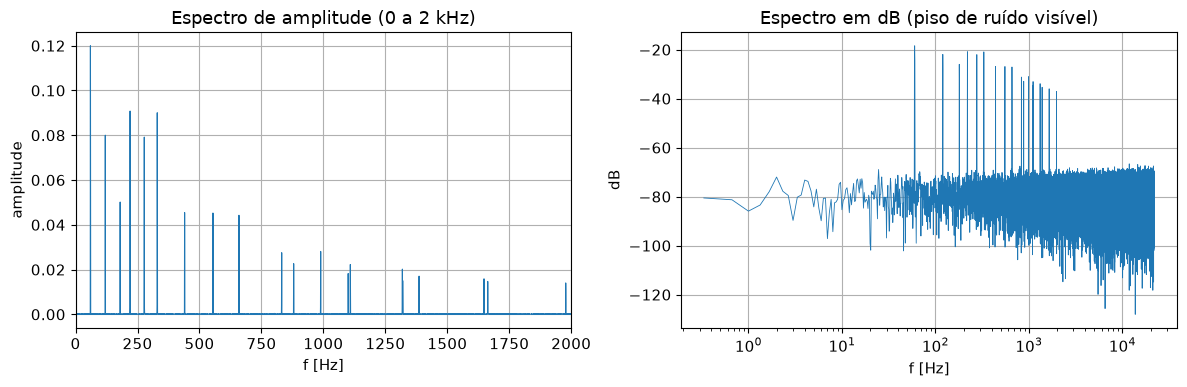

,f [Hz],amplitude,nota mais próxima,classificação
0,60.00,0.1200,B1,zumbido da rede
1,120.00,0.0800,B2,zumbido da rede
2,180.00,0.0502,F#3,zumbido da rede
3,220.00,0.0908,A3,A3 · harmônico 1
4,277.33,0.0792,C#4,C#4 · harmônico 1
5,329.67,0.0900,E4,E4 · harmônico 1
6,440.00,0.0455,A4,A3 · harmônico 2
7,554.33,0.0453,C#5,C#4 · harmônico 2
8,659.33,0.0442,E5,E4 · harmônico 2
9,831.67,0.0275,G#5,C#4 · harmônico 3


In [24]:
# 2.2 Espectro via FFT (janela de Hann para reduzir vazamento espectral)
def espectro(sig, fs):
    w = np.hanning(len(sig))
    X = fft.rfft(sig*w)
    f = fft.rfftfreq(len(sig), 1/fs)
    mag = 2*np.abs(X)/np.sum(w)          # amplitude de cada senoide
    return f, mag

f, mag = espectro(x, fs)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(f, mag, lw=.8); axs[0].set_xlim(0, 2000)
axs[0].set_title('Espectro de amplitude (0 a 2 kHz)'); axs[0].set_xlabel('f [Hz]'); axs[0].set_ylabel('amplitude')
axs[1].semilogx(f[1:], 20*np.log10(mag[1:]+1e-12), lw=.6)
axs[1].set_title('Espectro em dB (piso de ruído visível)'); axs[1].set_xlabel('f [Hz]'); axs[1].set_ylabel('dB')
plt.tight_layout(); plt.show()

# Detecção de picos e classificação (nota/harmônico ou zumbido)
idx, _ = signal.find_peaks(mag, height=0.01, distance=int(2/(fs/N)))
linhas = []
for i in idx:
    fp = f[i]
    classe = ''
    if min(abs(fp - 60*k) for k in (1, 2, 3, 4)) < 1.5:
        classe = 'zumbido da rede'
    else:
        melhor = None
        for nome, f0 in FUND.items():
            k = int(round(fp/f0))
            erro = abs(fp - k*f0)
            if k >= 1 and erro < 1.5 and (melhor is None or erro < melhor[0]):
                melhor = (erro, nome, k)
        if melhor: classe = f'{melhor[1]} · harmônico {melhor[2]}'
    linhas.append({'f [Hz]': round(fp, 2), 'amplitude': round(mag[i], 4),
                   'nota mais próxima': nome_nota(fp), 'classificação': classe})
tab_picos = pd.DataFrame(linhas)
display(tab_picos)

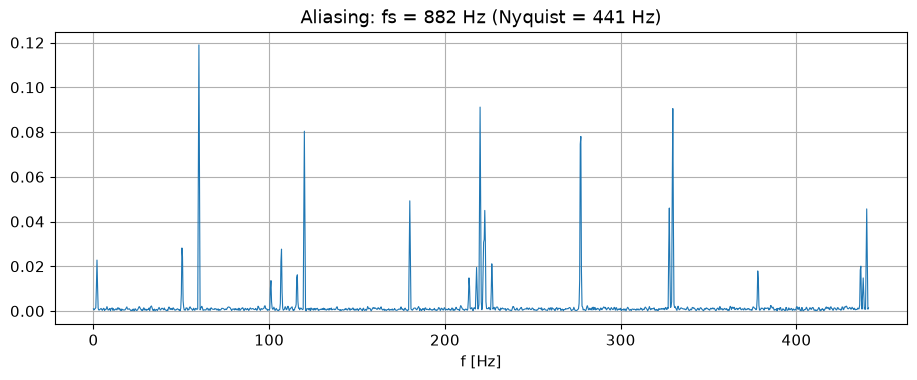

Componentes acima do Nyquist "dobram" para baixo (f_alias = |f - m*fs|): aparecem frequências que não existiam no sinal.


In [25]:
# 2.3 Nyquist na prática: reamostrar SEM filtro anti-aliasing
k = 50
x_alias = x[::k]; fs_alias = fs/k
f2, m2 = espectro(x_alias, fs_alias)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(f2, m2, lw=.8); ax.set_title(f'Aliasing: fs = {fs_alias:.0f} Hz (Nyquist = {fs_alias/2:.0f} Hz)')
ax.set_xlabel('f [Hz]'); plt.show()
print('Componentes acima do Nyquist "dobram" para baixo (f_alias = |f - m*fs|): aparecem frequências que não existiam no sinal.')

**Interpretação (escreva no relatório):** quais frequências dominam e a que notas/harmônicos correspondem? Onde está o zumbido de 60 Hz e seus harmônicos? Onde está o piso de ruído branco? Relacione com o que se ouve no sinal. O que o aliasing mostrou sobre a escolha de $f_s$?

---
# Etapa 3 · Filtrar e reconstruir (Unidade 3)
Duas abordagens:
- **A) Direto na frequência:** zera as faixas do zumbido e acima do corte na FFT e reconstrói com a **FFT inversa**.
- **B) Filtro IIR:** 3 filtros *notch* (60/120/180 Hz) em cascata + passa-baixas Butterworth, aplicados em fase zero.

O filtro B é o que será modelado com Laplace na Etapa 4.

In [26]:
# Parâmetros do filtro (compartilhados com a Etapa 4)
F_HUM = (60, 120, 180)    # zumbido e harmônicos [Hz]
Q_NOTCH = 30              # fator de qualidade -> largura de banda = f0/Q = 2 Hz
FC_LP = 2500              # corte do passa-baixas [Hz]
ORD_LP = 4

# ---- A) Máscara na frequência + FFT inversa
X = fft.rfft(x)
fx = fft.rfftfreq(N, 1/fs)
Hmask = np.ones_like(fx)
for f0 in F_HUM:
    Hmask[np.abs(fx - f0) <= 1.0] = 0.0
Hmask[fx > FC_LP] = 0.0
y_fft = fft.irfft(X*Hmask, n=N)

# ---- B) IIR: notches em cascata + Butterworth (SOS, fase zero com sosfiltfilt)
sos_list = []
for f0 in F_HUM:
    b, a = signal.iirnotch(f0, Q_NOTCH, fs)
    sos_list.append(signal.tf2sos(b, a))
sos_list.append(signal.butter(ORD_LP, FC_LP, 'low', fs=fs, output='sos'))
sos = np.vstack(sos_list)
y_iir = signal.sosfiltfilt(sos, x)

def snr_db(ref, est):
    return 10*np.log10(np.sum(ref**2)/np.sum((est-ref)**2))

if limpo is not None:
    res = pd.DataFrame({'SNR [dB]': [snr_db(limpo, x), snr_db(limpo, y_fft), snr_db(limpo, y_iir)]},
                       index=['ruidoso (antes)', 'A) máscara FFT + IFFT', 'B) notch + Butterworth'])
    display(res.round(2))

wavfile.write('sinal_filtrado_fft.wav', fs, (y_fft*32767).astype(np.int16))
wavfile.write('sinal_filtrado_iir.wav', fs, (y_iir*32767).astype(np.int16))
print('Antes:'); display(Audio(x, rate=fs))
print('Depois (A: FFT inversa):'); display(Audio(y_fft, rate=fs))
print('Depois (B: IIR):'); display(Audio(y_iir, rate=fs))

,SNR [dB]
ruidoso (antes),2.60
A) máscara FFT + IFFT,26.80
B) notch + Butterworth,23.31


Antes:


Depois (A: FFT inversa):


Depois (B: IIR):


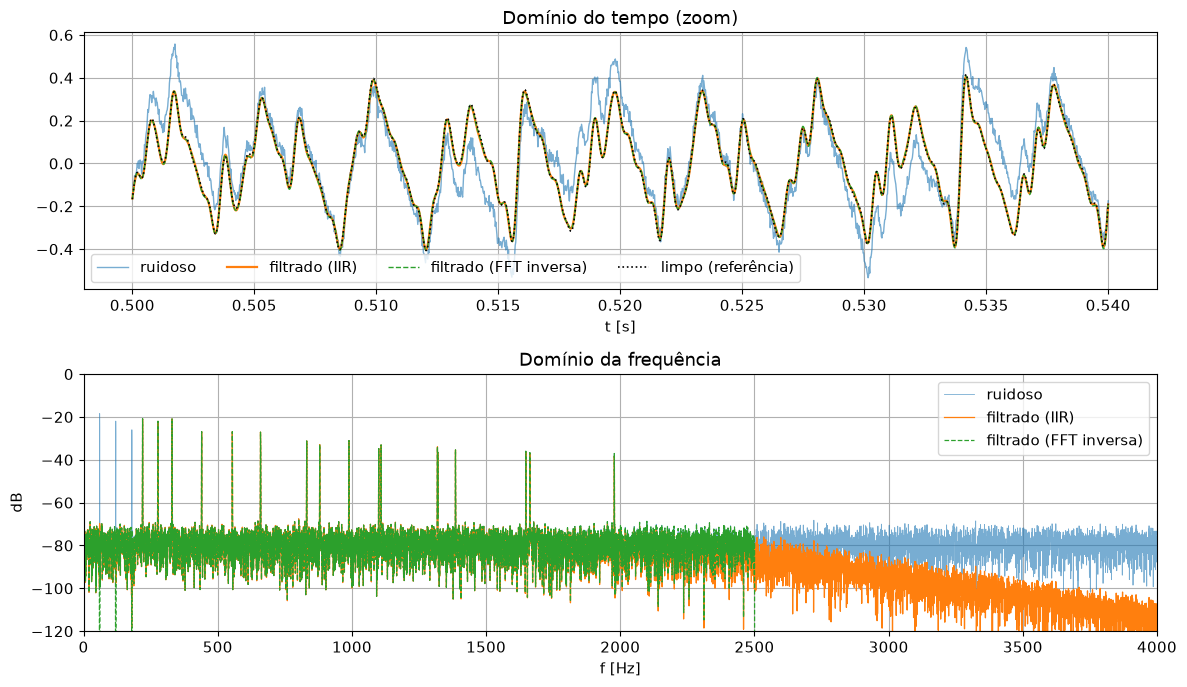

In [27]:
# 3.1 Comparação antes/depois: tempo e frequência
fig, axs = plt.subplots(2, 1, figsize=(12, 7))
sl = (t >= 0.50) & (t <= 0.54)
axs[0].plot(t[sl], x[sl], lw=1, alpha=.6, label='ruidoso')
axs[0].plot(t[sl], y_iir[sl], lw=1.6, label='filtrado (IIR)')
axs[0].plot(t[sl], y_fft[sl], lw=1, ls='--', label='filtrado (FFT inversa)')
if limpo is not None: axs[0].plot(t[sl], limpo[sl], 'k:', lw=1.2, label='limpo (referência)')
axs[0].set_title('Domínio do tempo (zoom)'); axs[0].set_xlabel('t [s]'); axs[0].legend(ncol=4)

f, m_x = espectro(x, fs); _, m_i = espectro(y_iir, fs); _, m_f = espectro(y_fft, fs)
axs[1].plot(f, 20*np.log10(m_x+1e-12), lw=.6, alpha=.6, label='ruidoso')
axs[1].plot(f, 20*np.log10(m_i+1e-12), lw=.9, label='filtrado (IIR)')
axs[1].plot(f, 20*np.log10(m_f+1e-12), lw=.9, ls='--', label='filtrado (FFT inversa)')
axs[1].set_xlim(0, 4000); axs[1].set_ylim(-120, 0)
axs[1].set_title('Domínio da frequência'); axs[1].set_xlabel('f [Hz]'); axs[1].set_ylabel('dB'); axs[1].legend()
plt.tight_layout(); plt.show()

**Interpretação (escreva no relatório):** por que o filtro está coerente com o que o espectro mostrou? O que muda na forma de onda e no som? Compare A e B: a máscara retangular na FFT causa *ringing* (Gibbs de novo!), enquanto o IIR tem transição suave. Por que usamos `sosfiltfilt` (fase zero) e qual o custo disso?

---
# Etapa 4 · O filtro como sistema linear (Unidade 4)
## 4.1 Aquecimento: filtro RC de 1ª ordem
$RC\,\dot v_o + v_o = v_i \;\xrightarrow{\mathcal L}\; H(s)=\dfrac{V_o(s)}{V_i(s)}=\dfrac{1}{RCs+1}$

Eq(H(s), 1/(C*R*s + 1))

Eq(h(t), exp(-t/(C*R))*Heaviside(t)/(C*R))

Eq(y_{degrau}(t), Heaviside(t) - exp(-t/(C*R))*Heaviside(t))

Polo único em s = -1/(RC) -> semiplano esquerdo -> estável. Frequência de corte f_c = 1/(2*pi*R*C).


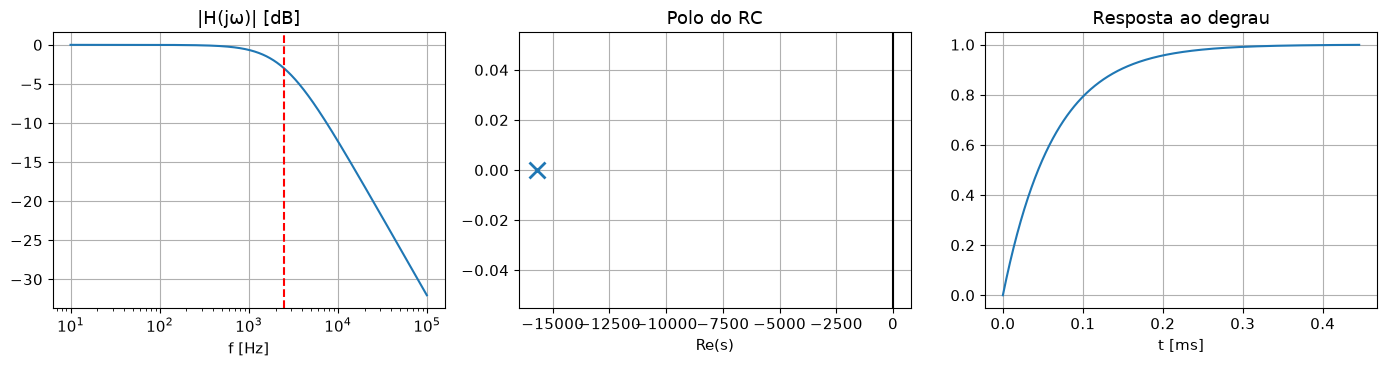

In [28]:
s, tsym = sp.symbols('s t')
Rs, Cs = sp.symbols('R C', positive=True)

H_rc = 1/(1 + Rs*Cs*s)
h_rc = sp.inverse_laplace_transform(H_rc, s, tsym)          # resposta ao impulso
y_deg = sp.inverse_laplace_transform(H_rc/s, s, tsym)       # resposta ao degrau
display(sp.Eq(sp.Function('H')(s), H_rc))
display(sp.Eq(sp.Function('h')(tsym), h_rc))
display(sp.Eq(sp.Function('y_{degrau}')(tsym), y_deg))
print('Polo único em s = -1/(RC) -> semiplano esquerdo -> estável. Frequência de corte f_c = 1/(2*pi*R*C).')

# Numérico: R = 1 kΩ, C escolhido para f_c = 2500 Hz
R_ = 1e3; C_ = 1/(2*np.pi*FC_LP*R_)
rc = signal.TransferFunction([1], [R_*C_, 1])
w = 2*np.pi*np.logspace(1, 5, 800)
w, mag_rc, ph_rc = signal.bode(rc, w)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
axs[0].semilogx(w/(2*np.pi), mag_rc); axs[0].axvline(FC_LP, color='r', ls='--'); axs[0].set_title('|H(jω)| [dB]'); axs[0].set_xlabel('f [Hz]')
axs[1].plot(np.real(rc.poles), np.imag(rc.poles), 'x', ms=12, mew=2); axs[1].axvline(0, color='k'); axs[1].set_title('Polo do RC'); axs[1].set_xlabel('Re(s)')
tt_, yy_ = signal.step(rc, N=500); axs[2].plot(tt_*1e3, yy_); axs[2].set_title('Resposta ao degrau'); axs[2].set_xlabel('t [ms]')
plt.tight_layout(); plt.show()

## 4.2 O filtro real da Etapa 3 como $H(s)$
- **Notch** (para cada $f_0$, $\omega_0=2\pi f_0$): $H_n(s)=\dfrac{s^2+\omega_0^2}{s^2+\frac{\omega_0}{Q}s+\omega_0^2}$. Zeros em $\pm j\omega_0$ e polos próximos, com parte real $-\omega_0/2Q$.
- **Passa-baixas Butterworth** de ordem 4 com $\omega_c=2\pi f_c$.
- $H(s)=H_{n,60}\,H_{n,120}\,H_{n,180}\,H_{LP}$ (cascata = produto).

In [29]:
def notch_analogico(f0, Q):
    w0 = 2*np.pi*f0
    z = np.array([1j*w0, -1j*w0])
    p = np.roots([1, w0/Q, w0**2])
    return z, p, 1.0

z_all, p_all, k_all = [], [], 1.0
for f0 in F_HUM:
    z_, p_, k_ = notch_analogico(f0, Q_NOTCH)
    z_all += list(z_); p_all += list(p_); k_all *= k_
zb, pb, kb = signal.butter(ORD_LP, 2*np.pi*FC_LP, 'low', analog=True, output='zpk')
z_all = np.array(z_all + list(zb)); p_all = np.array(p_all + list(pb)); k_all *= kb

# Função de transferência como razão de polinômios (para o relatório)
b_s, a_s = signal.zpk2tf(z_all, p_all, k_all)
s_ = sp.symbols('s')
print('Ordem do sistema:', len(p_all), '| nº de zeros:', len(z_all))
print('Zeros (rad/s):'); print(np.round(z_all, 2))
print('Polos (rad/s):'); print(np.round(p_all, 2))

estavel = np.all(np.real(p_all) < 0)
print(f'\nSistema estável (todos os polos com Re<0)? {estavel}')

# Tabela dos polos dos notches: a posição do polo controla a LARGURA do entalhe
linhas = []
for f0 in F_HUM:
    w0 = 2*np.pi*f0
    linhas.append({'f0 [Hz]': f0, 'Re(polo) = -w0/2Q [rad/s]': round(-w0/(2*Q_NOTCH), 3),
                   'Im(polo) ≈ w0 [rad/s]': round(w0*np.sqrt(1-1/(4*Q_NOTCH**2)), 2),
                   'largura de banda f0/Q [Hz]': f0/Q_NOTCH})
display(pd.DataFrame(linhas))

Ordem do sistema: 10 | nº de zeros: 6
Zeros (rad/s):
[0. +376.99j 0. -376.99j 0. +753.98j 0. -753.98j 0.+1130.97j 0.-1130.97j]
Polos (rad/s):
[-6.280000e+00  +376.94j -6.280000e+00  -376.94j -1.257000e+01  +753.88j
 -1.257000e+01  -753.88j -1.885000e+01 +1130.82j -1.885000e+01 -1130.82j
 -6.011180e+03+14512.27j -1.451227e+04 +6011.18j -1.451227e+04 -6011.18j
 -6.011180e+03-14512.27j]

Sistema estável (todos os polos com Re<0)? True


,f0 [Hz],Re(polo) = -w0/2Q [rad/s],Im(polo) ≈ w0 [rad/s],largura de banda f0/Q [Hz]
0,60,-6.283,376.94,2.0
1,120,-12.566,753.88,4.0
2,180,-18.850,1130.82,6.0


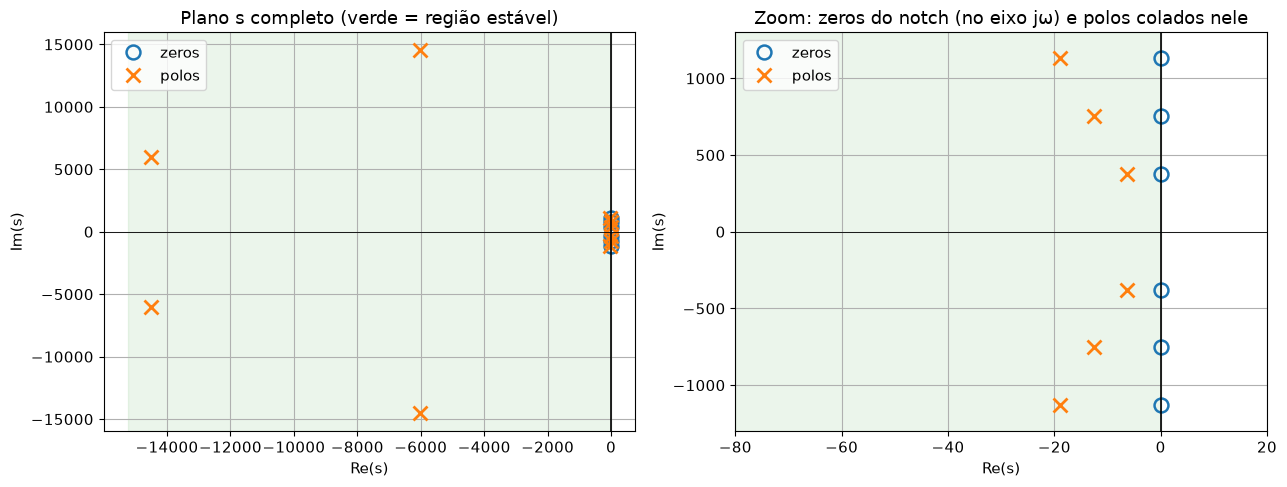

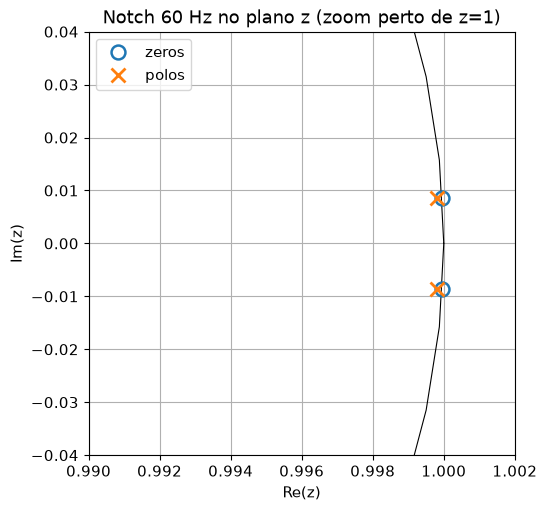

Raio dos polos |z| = [0.99986 0.99986] -> dentro do círculo unitário = estável (equivalente a Re(s)<0).


In [30]:
# 4.3 Mapa de polos e zeros (plano s)
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, zoom in zip(axs, [False, True]):
    ax.plot(np.real(z_all), np.imag(z_all), 'o', mfc='none', ms=10, mew=1.8, label='zeros')
    ax.plot(np.real(p_all), np.imag(p_all), 'x', ms=10, mew=2, label='polos')
    ax.axhline(0, color='k', lw=.6); ax.axvline(0, color='k', lw=1.2)
    ax.axvspan(ax.get_xlim()[0] if not zoom else -80, 0, alpha=.08, color='g')
    ax.set_xlabel('Re(s)'); ax.set_ylabel('Im(s)'); ax.legend(loc='upper left')
    if zoom:
        ax.set_xlim(-80, 20); ax.set_ylim(-1300, 1300)
        ax.set_title('Zoom: zeros do notch (no eixo jω) e polos colados nele')
    else:
        ax.set_title('Plano s completo (verde = região estável)')
plt.tight_layout(); plt.show()

# Plano z do filtro DIGITAL usado na Etapa 3 (notch de 60 Hz)
bz, az = signal.iirnotch(60, Q_NOTCH, fs)
zz, pz, _ = signal.tf2zpk(bz, az)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(np.cos(np.linspace(0, 2*np.pi, 400)), np.sin(np.linspace(0, 2*np.pi, 400)), 'k', lw=.8)
ax.plot(zz.real, zz.imag, 'o', mfc='none', ms=10, mew=1.8, label='zeros')
ax.plot(pz.real, pz.imag, 'x', ms=10, mew=2, label='polos')
ax.set_xlim(0.99, 1.002); ax.set_ylim(-0.04, 0.04); ax.legend(); ax.set_aspect('auto')
ax.set_title('Notch 60 Hz no plano z (zoom perto de z=1)'); ax.set_xlabel('Re(z)'); ax.set_ylabel('Im(z)')
plt.show()
print('Raio dos polos |z| =', np.round(np.abs(pz), 5), '-> dentro do círculo unitário = estável (equivalente a Re(s)<0).')

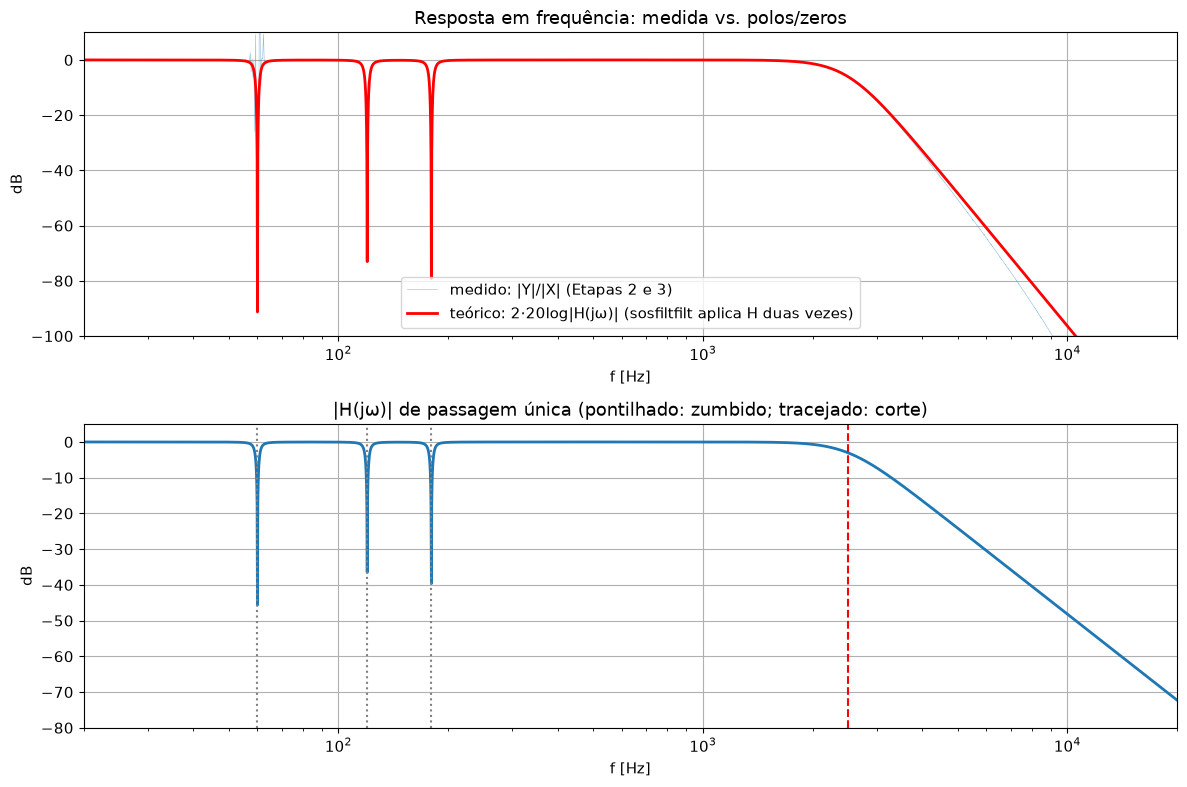

|H(j2π·   60 Hz)| = -240.00 dB
|H(j2π·  120 Hz)| = -240.00 dB
|H(j2π·  180 Hz)| = -240.00 dB
|H(j2π·  220 Hz)| =   -0.03 dB
|H(j2π· 1000 Hz)| =   -0.00 dB
|H(j2π· 2500 Hz)| =   -3.01 dB
|H(j2π· 5000 Hz)| =  -24.10 dB


In [31]:
# 4.4 A MESMA história em duas linguagens:
#     |H(jw)| calculado dos polos/zeros  x  razão medida entre os espectros (Etapa 2/3)
f_axis = np.logspace(np.log10(20), np.log10(20000), 3000)
_, Hjw = signal.freqs_zpk(z_all, p_all, k_all, worN=2*np.pi*f_axis)
H_db = 20*np.log10(np.abs(Hjw) + 1e-12)

w_hann = np.hanning(N)
Xw = fft.rfft(x*w_hann); Yw = fft.rfft(y_iir*w_hann); fr = fft.rfftfreq(N, 1/fs)
razao_db = 20*np.log10(np.abs(Yw)/(np.abs(Xw)+1e-12) + 1e-12)

fig, axs = plt.subplots(2, 1, figsize=(12, 8))
axs[0].semilogx(fr[1:], np.clip(razao_db[1:], -100, 10), lw=.4, alpha=.5, label='medido: |Y|/|X| (Etapas 2 e 3)')
axs[0].semilogx(f_axis, 2*H_db, 'r', lw=2, label='teórico: 2·20log|H(jω)| (sosfiltfilt aplica H duas vezes)')
axs[0].set_xlim(20, 20000); axs[0].set_ylim(-100, 10)
axs[0].set_title('Resposta em frequência: medida vs. polos/zeros'); axs[0].set_xlabel('f [Hz]'); axs[0].set_ylabel('dB'); axs[0].legend()

axs[1].semilogx(f_axis, H_db, lw=2); axs[1].set_ylim(-80, 5); axs[1].set_xlim(20, 20000)
for f0 in F_HUM: axs[1].axvline(f0, color='gray', ls=':')
axs[1].axvline(FC_LP, color='r', ls='--'); axs[1].set_title('|H(jω)| de passagem única (pontilhado: zumbido; tracejado: corte)')
axs[1].set_xlabel('f [Hz]'); axs[1].set_ylabel('dB')
plt.tight_layout(); plt.show()

for fq in [60, 120, 180, 220, 1000, 2500, 5000]:
    _, Hq = signal.freqs_zpk(z_all, p_all, k_all, worN=[2*np.pi*fq])
    print(f'|H(j2π·{fq:>5} Hz)| = {20*np.log10(abs(Hq[0])+1e-12):7.2f} dB')

**Interpretação (escreva no relatório):** onde estão os polos e os zeros? O sistema é estável e por quê? Os zeros em $\pm j\omega_0$ criam os vales exatamente em 60/120/180 Hz, que é onde o espectro da Etapa 2 mostrou o zumbido. Quanto mais próximo do eixo $j\omega$ está o polo (maior $Q$), mais estreito o entalhe. Os polos do Butterworth em arco no semiplano esquerdo definem a queda de 80 dB/década acima de $f_c$, que cortou o ruído de alta frequência. É a mesma história em duas linguagens: **polos/zeros no plano $s$** e **picos/vales no espectro**.

Neste projeto foi desenvolvido um sistema de filtragem para remover o zumbido da rede elétrica e o ruído de alta frequência de um sinal contaminado. A análise espectral da Etapa 2 mostrou que a interferência se concentrava na frequência fundamental da rede (60 Hz) e em suas harmônicas de 120 e 180 Hz, além de uma componente de ruído distribuída nas frequências altas. Com base nesse diagnóstico, foram projetados três filtros notch de segunda ordem em cascata, sintonizados nessas frequências, seguidos de um filtro passa-baixas Butterworth de 4ª ordem com frequência de corte de [$f_c$] Hz.

Os resultados confirmaram o comportamento previsto pela teoria. Os zeros dos filtros notch, posicionados sobre o eixo $j\omega$, eliminaram os picos de 60, 120 e 180 Hz, com atenuação de [X] dB, enquanto o restante do espectro foi pouco alterado devido à proximidade entre polos e zeros fora da frequência de entalhe. O filtro Butterworth atenuou o ruído acima de $f_c$ com a inclinação esperada de 80 dB/década, sem introduzir ondulação na banda passante. Todos os polos do sistema completo estão no semiplano esquerdo, o que garante sua estabilidade.

O projeto também evidenciou os compromissos envolvidos na escolha dos parâmetros. Um fator de qualidade maior estreita o entalhe e preserva mais o sinal útil, mas prolonga o transitório e deixa o filtro sensível a pequenas variações na frequência da rede. Da mesma forma, uma frequência de corte mais baixa remove mais ruído, mas pode atenuar componentes relevantes do sinal. O valor $Q = $ [valor] foi escolhido como um equilíbrio entre esses efeitos.

Por fim, o trabalho mostrou na prática a equivalência entre a descrição de um sistema no plano $s$ e sua resposta em frequência: a posição de polos e zeros permite prever, antes mesmo da simulação, onde o espectro terá picos e vales e com que rapidez a resposta decai. Como possíveis melhorias, poderiam ser investigados filtros notch adaptativos, capazes de acompanhar variações na frequência da rede, e a filtragem com fase zero para evitar distorção de fase no sinal processado.